# PCA on the labelled, non-deformed training data

- **D_A**: training rows with a label (`Class_Label` 0–10)
- **D_B**: training rows without a label (`Class_Label = -1`)
- **D_A_clean**: rows of D_A with `is_deformed = 0`

Steps: load the data → standardize each of the 768 dimensions using D_A_clean's mean/std (across all classes) → fit PCA on D_A_clean → print explained variance for the top 10 components.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

DATA_DIR = "ie-643-2026-programming-challenge"
train = pd.read_csv(f"{DATA_DIR}/Train_Data.csv")

feat_cols = [c for c in train.columns if c.startswith("e")]   # e0 ... e767
print("number of feature columns:", len(feat_cols))

number of feature columns: 768


## 1. Split into D_A (labelled) and D_B (unlabelled)

In [2]:
D_A = train[train["Class_Label"] != -1].reset_index(drop=True)
D_B = train[train["Class_Label"] == -1].reset_index(drop=True)

X_A = D_A[feat_cols].values      # shape (n_A, 768)
y_A = D_A["Class_Label"].values
d_A = D_A["is_deformed"].values  # 1 = deformed, 0 = clean
X_B = D_B[feat_cols].values      # shape (n_B, 768)

print("D_A:", X_A.shape, "| D_B:", X_B.shape)

counts = pd.crosstab(D_A["Class_Label"], D_A["is_deformed"]).rename(columns={0: "clean", 1: "deformed"})
counts["total"] = counts.sum(axis=1)
counts.loc["all"] = counts.sum()
print("points per class in D_A:")
print(counts.to_string())

D_A: (1284, 768) | D_B: (792, 768)
points per class in D_A:
is_deformed  clean  deformed  total
Class_Label                        
0               46       404    450
1                8        38     46
2                6        42     48
3                6        85     91
4               10        64     74
5               17        98    115
6               14       127    141
7                5        92     97
8                3        47     50
9               13       119    132
10               8        32     40
all            136      1148   1284


## 2. Keep only the non-deformed points of D_A

In [3]:
X_A_clean = X_A[d_A == 0]
y_A_clean = y_A[d_A == 0]

print("D_A_clean:", X_A_clean.shape)
# Note: with n points, PCA has at most n-1 components with nonzero variance (here n is well below 768)

D_A_clean: (136, 768)


## 3. Normalize (per dimension, across all classes, using D_A_clean's statistics)

For each dimension j: `x'_ij = (x_ij - mu_j) / sigma_j`, where `mu_j`, `sigma_j` are computed over all points of D_A_clean.
D_B is normalized with the **same** `mu`, `sigma` (not recomputed).

In [4]:
mu = X_A_clean.mean(axis=0)       # 768 means
sigma = X_A_clean.std(axis=0)     # 768 standard deviations

X_A_clean_norm = (X_A_clean - mu) / sigma
X_B_norm = (X_B - mu) / sigma

print("D_A_clean after normalization: mean range [%.2e, %.2e], std range [%.3f, %.3f]"
      % (X_A_clean_norm.mean(0).min(), X_A_clean_norm.mean(0).max(),
         X_A_clean_norm.std(0).min(), X_A_clean_norm.std(0).max()))

D_A_clean after normalization: mean range [-5.90e-15, 4.33e-15], std range [1.000, 1.000]


## 4. PCA on D_A_clean

In [5]:
pca = PCA()            # keep all components, so we can see the full spectrum
pca.fit(X_A_clean_norm)

evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

top10 = pd.DataFrame({
    "PC": np.arange(1, 11),
    "explained variance (%)": (100 * evr[:10]).round(2),
    "cumulative (%)": (100 * cum[:10]).round(2),
})
print(top10.to_string(index=False))

 PC  explained variance (%)  cumulative (%)
  1                   13.32           13.32
  2                    6.57           19.89
  3                    5.75           25.64
  4                    5.04           30.68
  5                    4.33           35.01
  6                    3.51           38.52
  7                    3.10           41.63
  8                    2.68           44.31
  9                    2.31           46.61
 10                    1.95           48.57


In [6]:
# How many components are needed for a given share of the variance
for t in [0.5, 0.8, 0.9, 0.95, 0.99]:
    print(f"{int(t*100)}% variance needs {np.searchsorted(cum, t) + 1} components")

50% variance needs 11 components
80% variance needs 43 components
90% variance needs 69 components
95% variance needs 89 components
99% variance needs 118 components


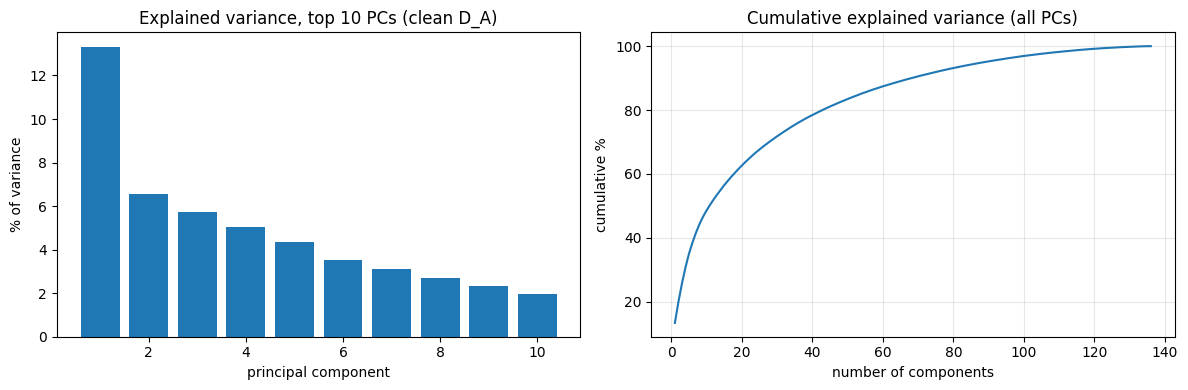

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(np.arange(1, 11), 100 * evr[:10])
ax[0].set(title="Explained variance, top 10 PCs (clean D_A)", xlabel="principal component", ylabel="% of variance")
ax[1].plot(np.arange(1, len(cum) + 1), 100 * cum)
ax[1].set(title="Cumulative explained variance (all PCs)", xlabel="number of components", ylabel="cumulative %")
ax[1].grid(alpha=.3)
plt.tight_layout()
plt.show()

## 5. t-SNE on the clean points, using the top 118 PCs (99% of variance)

Each clean point of D_A is represented by its coordinates on the first 118 principal components, and t-SNE maps those to 2-D.
t-SNE only preserves *local* neighbourhoods: points that end up close together were close in the 118-D space,
but distances between far-apart groups and the size of a cluster carry little meaning.

top 118 PCs explain 99.02% of the variance of D_A_clean


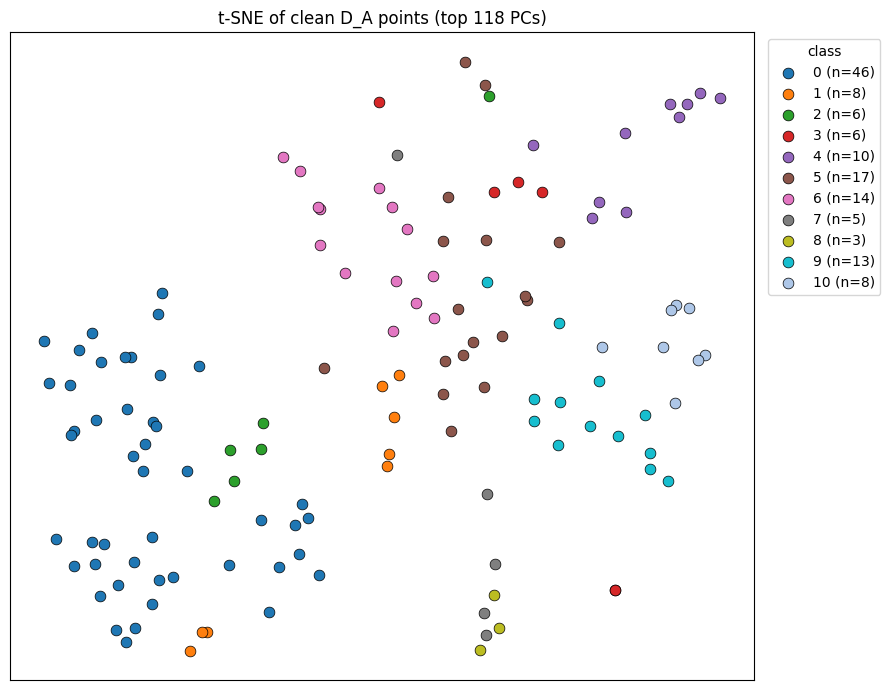

In [8]:
from sklearn.manifold import TSNE

N_PC = 118
print(f"top {N_PC} PCs explain {100 * cum[N_PC - 1]:.2f}% of the variance of D_A_clean")

Z_clean = pca.transform(X_A_clean_norm)[:, :N_PC]      # (136, 118)

# 11 distinguishable colours (tab10 only has 10)
CLASS_COLORS = plt.cm.tab20(np.linspace(0, 1, 20))[[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 1]]

tsne_clean = TSNE(n_components=2, perplexity=30, init="pca", random_state=0)
T_clean = tsne_clean.fit_transform(Z_clean)

fig, ax = plt.subplots(figsize=(9, 7))
for c in range(11):
    sel = y_A_clean == c
    ax.scatter(T_clean[sel, 0], T_clean[sel, 1], s=60, color=CLASS_COLORS[c],
               edgecolor="k", lw=.5, label=f"{c} (n={sel.sum()})")
ax.set(title=f"t-SNE of clean D_A points (top {N_PC} PCs)", xticks=[], yticks=[])
ax.legend(title="class", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 6. t-SNE with the deformed points added

The deformed points of D_A are normalized with the **clean** `mu`, `sigma` and projected onto the **same** 118 PCs
(fitted on clean points only). t-SNE cannot place new points into an existing map, so it is re-run on clean + deformed together;
the layout will therefore differ from the plot above.

- Left: coloured by class. Clean points are large stars with a black edge, deformed points are small dots.
- Right: the same map coloured only by clean vs deformed.

If deformation kept points near their class, the dots of each colour would sit around the stars of the same colour.

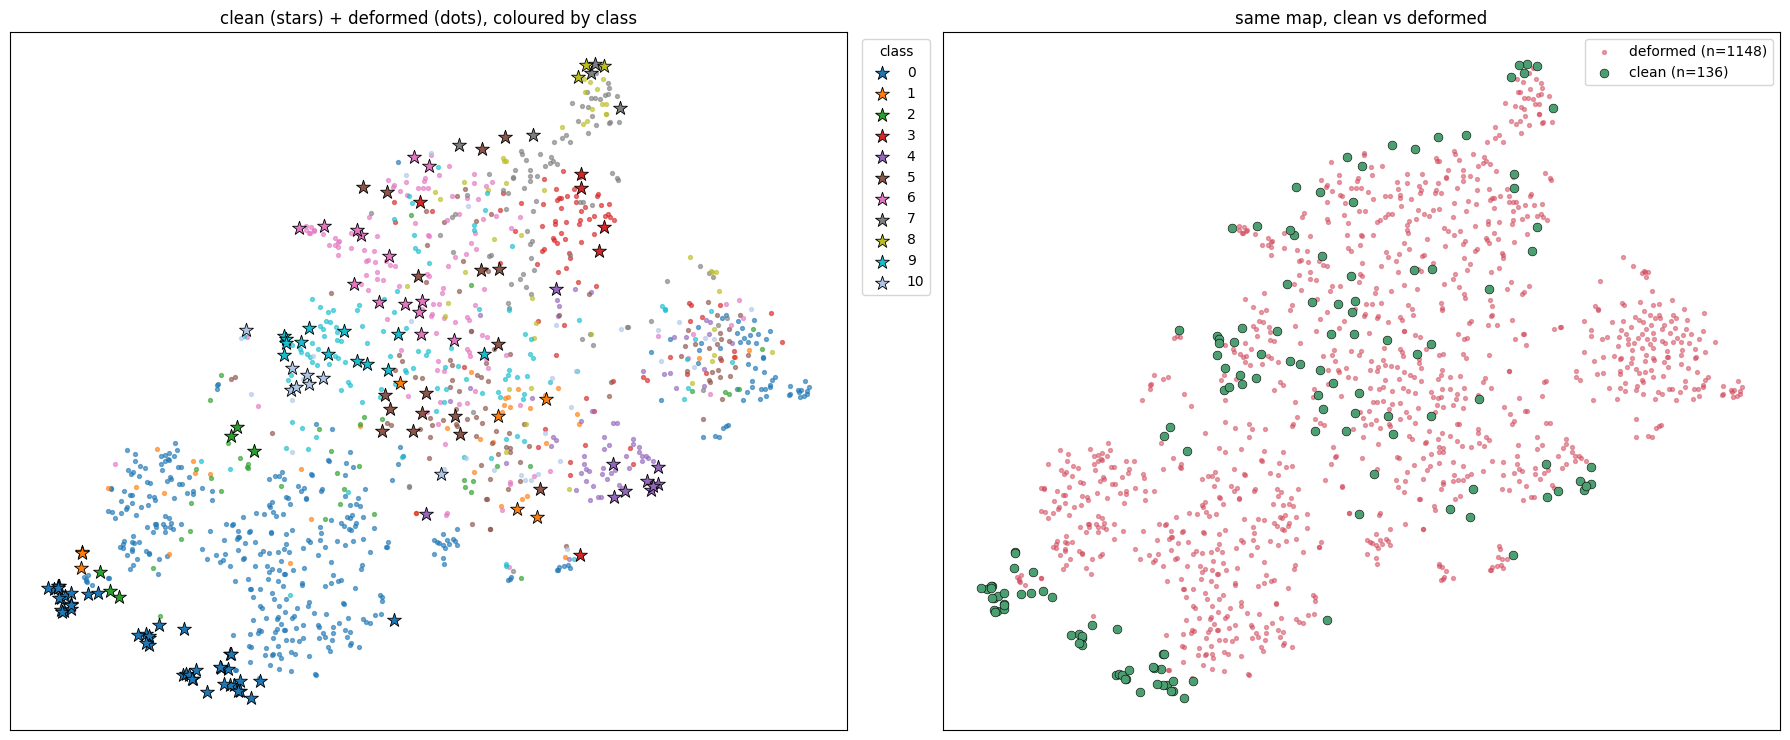

In [9]:
X_A_def = X_A[d_A == 1]
y_A_def = y_A[d_A == 1]
X_A_def_norm = (X_A_def - mu) / sigma                   # clean statistics, not recomputed
Z_def = pca.transform(X_A_def_norm)[:, :N_PC]           # (1148, 118)

Z_both = np.vstack([Z_clean, Z_def])
y_both = np.concatenate([y_A_clean, y_A_def])
is_def = np.concatenate([np.zeros(len(Z_clean), bool), np.ones(len(Z_def), bool)])

tsne_both = TSNE(n_components=2, perplexity=30, init="pca", random_state=0)
T_both = tsne_both.fit_transform(Z_both)

fig, ax = plt.subplots(1, 2, figsize=(18, 7.5))
for c in range(11):
    sel = (y_both == c) & is_def
    ax[0].scatter(T_both[sel, 0], T_both[sel, 1], s=8, color=CLASS_COLORS[c], alpha=.6)
for c in range(11):
    sel = (y_both == c) & ~is_def
    ax[0].scatter(T_both[sel, 0], T_both[sel, 1], s=110, marker="*", color=CLASS_COLORS[c],
                  edgecolor="k", lw=.6, label=str(c))
ax[0].set(title="clean (stars) + deformed (dots), coloured by class", xticks=[], yticks=[])
ax[0].legend(title="class", bbox_to_anchor=(1.01, 1), loc="upper left")

ax[1].scatter(T_both[is_def, 0], T_both[is_def, 1], s=8, c="#D1495B", alpha=.5, label=f"deformed (n={is_def.sum()})")
ax[1].scatter(T_both[~is_def, 0], T_both[~is_def, 1], s=40, c="#4C9F70", edgecolor="k", lw=.4, label=f"clean (n={(~is_def).sum()})")
ax[1].set(title="same map, clean vs deformed", xticks=[], yticks=[])
ax[1].legend()
plt.tight_layout()
plt.show()

## 7. Can a non-linear map to 2-D separate the clean classes?

We train a small network `f: R^d -> R^2` on the clean points' PCA coordinates with a loss that rewards good clusters,
and compare it with a **linear** map `R^d -> R^2` trained with the same loss. If the MLP does better on **held-out**
points, the non-linearity is helping.

**Setup**
- **Losses**
  - **NCA**: directly maximizes leave-one-out nearest-neighbour accuracy.
  - **Soft silhouette**: the silhouette score with a soft-min over the other classes so it is differentiable.
  - Both weight every point by 1/(class size), so class 0 does not dominate.
- **Models**
  - `linear`: 2-D output with no hidden layer.
  - `mlp`: hidden layers 64 → 32 with GELU and dropout 0.3, then a linear 2-D output.
- **Baselines** (no training):
  - k-NN directly in the PCA space;
  - the first 2 PCs.
- **Cross-validation**
  - Stratified 3-fold, repeated 5 times. Class 8 has only 3 clean points, so 3 folds is the most that keeps every class in every fold.
  - Every fold has the same class proportions as the full clean set; the table below checks this.
- **Metrics on the validation fold**: k-NN accuracy (k = 1, 5), plain and balanced. The k-NN is fitted on the *training* points' embeddings and predicts the *validation* points.
  - `acc`: fraction of validation points predicted correctly; class 0 dominates it.
  - `bal_acc`: accuracy computed per class, then averaged over the 11 classes. Chance is 1/11 ≈ 0.09. **This is the main number.**

**Decisions to be aware of (change them in the config cell if you disagree)**
1. **Normalization and PCA are re-fitted inside every fold, on the training part only** (`PCA_INSIDE_FOLD = True`).
   - If the PCA from section 4 were reused, the validation points would have helped choose the axes. That leak is small (PCA uses no labels) but real.
   - Side effect: a fold has only ~90 training points, so 99% of the variance needs fewer than 90 PCs (about 80), not 118.
   - Set `PCA_INSIDE_FOLD = False` to use the global 118-PC projection instead.
2. **No early stopping.** Every model trains for a fixed `N_STEPS`.
   - Stopping on the validation fold and then reporting that same fold would overstate the results.
   - The learning curves (7.4) show whether `N_STEPS` is too long or too short; change it once for all models, not per fold.
3. **Validation folds hold ~45 points**, with 1 point from class 8 and 2 each from classes 2 and 3, so individual numbers are noisy. Compare means ± std across the 15 folds, not single folds.

In [21]:
import time, warnings
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_samples, balanced_accuracy_score   # silhouette_samples: only for the loss sanity check

# ---------------- configuration ----------------
N_SPLITS        = 3        # class 8 has 3 clean points -> 3 folds is the max that keeps every class in every fold
N_REPEATS       = 5        # repeat the 3-fold split with different shuffles -> 15 train/val splits
VAR_KEEP        = 0.99     # share of variance kept by the PCA fitted inside each fold
PCA_INSIDE_FOLD = True     # False -> use one PCA fitted on all 136 clean points (val points leak into the axes)
LOSSES          = ["nca", "silhouette"]
ARCHS           = ["linear", "mlp"]
HIDDEN          = (64, 32)
DROPOUT         = 0.3
INPUT_NOISE     = 0.05     # std of Gaussian noise added to the (scaled) inputs during training
LR              = 1e-3
WEIGHT_DECAY    = 1e-2     # AdamW (decoupled) weight decay
N_STEPS         = 2000     # full-batch steps, fixed for every model (no early stopping on the val fold)
EVAL_EVERY      = 100      # log validation metrics every this many steps (for the learning curves only)
SILH_TAU        = 0.1      # soft-min temperature of the soft silhouette (relative to the typical distance)
SEED            = 0
N_CLASSES       = 11

CLASS_COLORS = plt.cm.tab20(np.linspace(0, 1, 20))[[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 1]]
np.random.seed(SEED); torch.manual_seed(SEED)
assert set(np.unique(y_A_clean)) == set(range(N_CLASSES)), "expected all 11 classes among the clean points"
print("clean points:", X_A_clean.shape, "| torch", torch.__version__)

clean points: (136, 768) | torch 2.12.1


### 7.1 Folds, and a check that train and validation have the same class distribution

In [22]:
rskf  = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
folds = list(rskf.split(X_A_clean, y_A_clean))

overall = np.bincount(y_A_clean, minlength=N_CLASSES) / len(y_A_clean)
rows = []
for k, (tr, va) in enumerate(folds):
    assert len(np.intersect1d(tr, va)) == 0
    c_tr = np.bincount(y_A_clean[tr], minlength=N_CLASSES)
    c_va = np.bincount(y_A_clean[va], minlength=N_CLASSES)
    assert (c_tr >= 2).all() and (c_va >= 1).all(), f"fold {k}: some class missing from train or val"
    rows.append(dict(fold=k, n_train=len(tr), n_val=len(va),
                     min_train_per_class=c_tr.min(), min_val_per_class=c_va.min(),
                     max_abs_diff_pct=round(100 * np.abs(c_tr / len(tr) - c_va / len(va)).max(), 2)))
fold_check = pd.DataFrame(rows)
print(f"max |train share - val share| over all classes and folds: {fold_check.max_abs_diff_pct.max():.2f} percentage points")
display(fold_check)

# class counts for the 3 folds of the first repeat
first = {}
for k, (tr, va) in enumerate(folds[:N_SPLITS]):
    first[(f"fold {k}", "train")] = np.bincount(y_A_clean[tr], minlength=N_CLASSES)
    first[(f"fold {k}", "val")]   = np.bincount(y_A_clean[va], minlength=N_CLASSES)
first_df = pd.DataFrame(first, index=pd.Index(range(N_CLASSES), name="class"))
first_df[("all", "clean")] = np.bincount(y_A_clean, minlength=N_CLASSES)
display(first_df)

max |train share - val share| over all classes and folds: 2.32 percentage points


,fold,n_train,n_val,min_train_per_class,min_val_per_class,max_abs_diff_pct
0,0,90,46,2,1,2.32
1,1,91,45,2,1,2.32
2,2,91,45,2,1,2.30
3,3,90,46,2,1,2.32
4,4,91,45,2,1,2.32
5,5,91,45,2,1,2.30
6,6,90,46,2,1,2.32
7,7,91,45,2,1,2.32
8,8,91,45,2,1,2.30
9,9,90,46,2,1,2.32


fold 0     fold 1     fold 2       all
       train val  train val  train val clean
class                                       
0         30  16     31  15     31  15    46
1          6   2      5   3      5   3     8
2          4   2      4   2      4   2     6
3          4   2      4   2      4   2     6
4          7   3      7   3      6   4    10
5         11   6     11   6     12   5    17
6          9   5      9   5     10   4    14
7          3   2      4   1      3   2     5
8          2   1      2   1      2   1     3
9          9   4      8   5      9   4    13
10         5   3      6   2      5   3     8

### 7.2 Building blocks: preprocessing, models, losses, metrics

In [23]:
def fit_preprocess(X_fit, var_keep=VAR_KEEP, n_components=None):
    # Standardize with X_fit's statistics, PCA fitted on X_fit, then one global rescale.
    # Returns a function that applies exactly the same steps to any other points.
    mu_ = X_fit.mean(axis=0)
    sd_ = X_fit.std(axis=0)
    sd_[sd_ == 0] = 1.0
    pca_ = PCA(n_components=n_components if n_components is not None else var_keep, svd_solver="full")
    Z_fit = pca_.fit_transform((X_fit - mu_) / sd_)
    scale_ = Z_fit.std()           # one number for all PCs: keeps their relative geometry, puts inputs at O(1)

    def transform(X):
        return pca_.transform((X - mu_) / sd_) / scale_
    return transform, pca_.n_components_


def make_model(arch, d_in):
    if arch == "linear":
        return nn.Linear(d_in, 2)
    if arch == "mlp":
        layers, d = [], d_in
        for h in HIDDEN:
            layers += [nn.Linear(d, h), nn.GELU(), nn.Dropout(DROPOUT)]
            d = h
        layers.append(nn.Linear(d, 2))          # linear output, no activation
        return nn.Sequential(*layers)
    raise ValueError(arch)


def class_weights(y):
    # weight 1 / (class size), normalized to sum to 1 -> every class contributes equally
    counts = torch.bincount(y, minlength=N_CLASSES).float()
    w = 1.0 / counts[y]
    return w / w.sum()


def sq_dists(Z):
    sq = (Z * Z).sum(1)
    return (sq[:, None] + sq[None, :] - 2 * Z @ Z.T).clamp_min(0.0)


def nca_loss(Z, y, w):
    # p_ij = softmax_j(-||z_i - z_j||^2) over j != i ;  loss = -sum_i w_i log( sum_{j in class(i)} p_ij )
    n = len(y)
    eye = torch.eye(n, dtype=torch.bool)
    logp = torch.log_softmax((-sq_dists(Z)).masked_fill(eye, float("-inf")), dim=1)
    same = (y[:, None] == y[None, :]) & ~eye
    valid = same.any(1)                         # points whose class has another member in the batch
    log_p_same = torch.logsumexp(logp[valid].masked_fill(~same[valid], float("-inf")), dim=1)
    return -(w[valid] * log_p_same).sum() / w[valid].sum()


def soft_silhouette_loss(Z, y, w, tau=SILH_TAU):
    # s_i = (b_i - a_i) / max(a_i, b_i)
    #   a_i = mean distance to the other members of its own class
    #   b_i = soft-min over the other classes of the mean distance to that class
    n = len(y)
    eye = torch.eye(n, dtype=torch.bool)
    D = torch.sqrt(sq_dists(Z) + 1e-9).masked_fill(eye, 0.0)
    onehot = F.one_hot(y, N_CLASSES).float()
    counts = onehot.sum(0)
    sum_to_class = D @ onehot                                    # (n, C)
    own_cnt = counts[y]
    a = sum_to_class.gather(1, y[:, None]).squeeze(1) / (own_cnt - 1).clamp_min(1)
    mean_to_class = sum_to_class / counts.clamp_min(1)
    other = (onehot == 0) & (counts > 0)[None, :]
    typical = ((mean_to_class * other).sum(1) / other.sum(1)).detach()   # makes tau scale-free
    soft = torch.softmax((-mean_to_class / (tau * typical[:, None])).masked_fill(~other, float("-inf")), dim=1)
    b = (soft * mean_to_class.masked_fill(~other, 0.0)).sum(1)
    s = (b - a) / torch.maximum(a, b).clamp_min(1e-9)
    valid = own_cnt > 1                         # silhouette is undefined for a class with one point
    return -(w[valid] * s[valid]).sum() / w[valid].sum()


LOSS_FNS = {"nca": nca_loss, "silhouette": soft_silhouette_loss}


def evaluate(E_tr, y_tr, E_va, y_va):
    # k-NN fitted on the training embeddings, predicting the validation embeddings
    out = {}
    for k in (1, 5):
        pred = KNeighborsClassifier(n_neighbors=k).fit(E_tr, y_tr).predict(E_va)
        out[f"knn{k}_acc"] = float((pred == y_va).mean())
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            out[f"knn{k}_bal_acc"] = float(balanced_accuracy_score(y_va, pred))
    return out


def embed(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.as_tensor(X, dtype=torch.float32)).numpy()


def train_embedder(arch, loss_name, X_tr, y_tr, X_va=None, y_va=None, seed=SEED):
    torch.manual_seed(seed)
    Xt = torch.as_tensor(X_tr, dtype=torch.float32)
    yt = torch.as_tensor(y_tr, dtype=torch.long)
    w = class_weights(yt)
    model = make_model(arch, Xt.shape[1])
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    loss_fn = LOSS_FNS[loss_name]
    history = []
    for step in range(1, N_STEPS + 1):
        model.train()
        x_in = Xt + INPUT_NOISE * torch.randn_like(Xt) if INPUT_NOISE > 0 else Xt
        loss = loss_fn(model(x_in), yt, w)
        if not torch.isfinite(loss):
            raise RuntimeError(f"{arch}+{loss_name}: non-finite loss at step {step}")
        opt.zero_grad()
        loss.backward()
        opt.step()
        if X_va is not None and (step % EVAL_EVERY == 0 or step == N_STEPS):
            m = evaluate(embed(model, X_tr), y_tr, embed(model, X_va), y_va)
            history.append(dict(step=step, train_loss=float(loss), **m))
    return model, history

In [24]:
# Sanity checks for the losses on toy data (cheap; should all print True)
_y = torch.tensor([0, 0, 1, 1, 2, 2])
_w = class_weights(_y)
_good = torch.tensor([[0, 0], [0, .1], [5, 5], [5, 5.1], [-5, 5], [-5, 5.1]])   # tight, far-apart clusters
_bad  = torch.randn(6, 2, generator=torch.Generator().manual_seed(0))
print("NCA lower for good clusters:       ", nca_loss(_good, _y, _w).item() < nca_loss(_bad, _y, _w).item())
print("soft silhouette near -1 for good:  ", soft_silhouette_loss(_good, _y, _w).item() < -0.95)
print("soft silhouette is scale-invariant:", torch.isclose(soft_silhouette_loss(_bad, _y, _w),
                                                           soft_silhouette_loss(10 * _bad, _y, _w), atol=1e-5).item())
print("soft silhouette ~ sklearn silhouette (tau small):",
      np.isclose(-soft_silhouette_loss(_bad, _y, _w, tau=1e-3).item(),
                 silhouette_samples(_bad.numpy(), _y.numpy()).mean(), atol=1e-3))

NCA lower for good clusters:        True
soft silhouette near -1 for good:   True
soft silhouette is scale-invariant: True
soft silhouette ~ sklearn silhouette (tau small): True


### 7.3 Cross-validation

In [25]:
if not PCA_INSIDE_FOLD:
    global_transform, global_npc = fit_preprocess(X_A_clean)     # 99% of variance on all clean points -> 118 PCs

results, histories, fold0 = [], [], {}
t0 = time.time()
for f, (tr, va) in enumerate(folds):
    if PCA_INSIDE_FOLD:
        transform, n_pc = fit_preprocess(X_A_clean[tr])          # fitted on the training part only
    else:
        transform, n_pc = global_transform, global_npc
    Z_tr, Z_va = transform(X_A_clean[tr]), transform(X_A_clean[va])
    y_tr, y_va = y_A_clean[tr], y_A_clean[va]

    baselines = {f"PCA space ({n_pc}-D, no network)": (Z_tr, Z_va),
                 "first 2 PCs (no network)":           (Z_tr[:, :2], Z_va[:, :2])}
    for name, (E_tr, E_va) in baselines.items():
        results.append(dict(fold=f, model=name.replace(f"{n_pc}-D", "d-D"), n_pc=n_pc, **evaluate(E_tr, y_tr, E_va, y_va)))
        if f == 0:
            fold0[name] = (E_tr, E_va, y_tr, y_va)

    for loss_name in LOSSES:
        for arch in ARCHS:
            name = f"{arch} + {loss_name}"
            model, hist = train_embedder(arch, loss_name, Z_tr, y_tr, Z_va, y_va, seed=SEED + f)
            final = {k: v for k, v in hist[-1].items() if k not in ("step", "train_loss")}
            results.append(dict(fold=f, model=name, n_pc=n_pc, **final))
            histories += [dict(fold=f, model=name, **h) for h in hist]
            if f == 0:
                fold0[name] = (embed(model, Z_tr), embed(model, Z_va), y_tr, y_va)
    print(f"fold {f + 1:2d}/{len(folds)} done  (PCs in this fold: {n_pc})  elapsed {time.time() - t0:.0f}s")

res = pd.DataFrame(results)
hist_df = pd.DataFrame(histories)

fold  1/15 done  (PCs in this fold: 80)  elapsed 6s
fold  2/15 done  (PCs in this fold: 81)  elapsed 11s
fold  3/15 done  (PCs in this fold: 82)  elapsed 17s
fold  4/15 done  (PCs in this fold: 81)  elapsed 22s
fold  5/15 done  (PCs in this fold: 81)  elapsed 28s
fold  6/15 done  (PCs in this fold: 81)  elapsed 34s
fold  7/15 done  (PCs in this fold: 80)  elapsed 39s
fold  8/15 done  (PCs in this fold: 81)  elapsed 45s
fold  9/15 done  (PCs in this fold: 82)  elapsed 50s
fold 10/15 done  (PCs in this fold: 81)  elapsed 56s
fold 11/15 done  (PCs in this fold: 81)  elapsed 62s
fold 12/15 done  (PCs in this fold: 82)  elapsed 67s
fold 13/15 done  (PCs in this fold: 81)  elapsed 73s
fold 14/15 done  (PCs in this fold: 81)  elapsed 79s
fold 15/15 done  (PCs in this fold: 81)  elapsed 84s


15 validation folds | chance: balanced acc = 0.091, always-predict-class-0 acc = 0.338


knn1_acc        knn1_bal_acc        knn5_acc  \
                                mean    std         mean    std     mean   
model                                                                      
PCA space (d-D, no network)    0.828  0.048        0.718  0.077    0.772   
mlp + nca                      0.711  0.081        0.585  0.107    0.698   
linear + silhouette            0.685  0.053        0.545  0.084    0.685   
mlp + silhouette               0.665  0.064        0.513  0.092    0.660   
linear + nca                   0.637  0.059        0.471  0.081    0.638   
first 2 PCs (no network)       0.507  0.071        0.330  0.090    0.528   

                                   knn5_bal_acc         
                               std         mean    std  
model                                                   
PCA space (d-D, no network)  0.045        0.620  0.071  
mlp + nca                    0.085        0.555  0.120  
linear + silhouette          0.049        0.541  0.071  
mlp + silhouette             0.054        0.491  0.075  
linear + nca                 0.062        0.459  0.089  
first 2 PCs (no network)     0.054        0.305  0.061

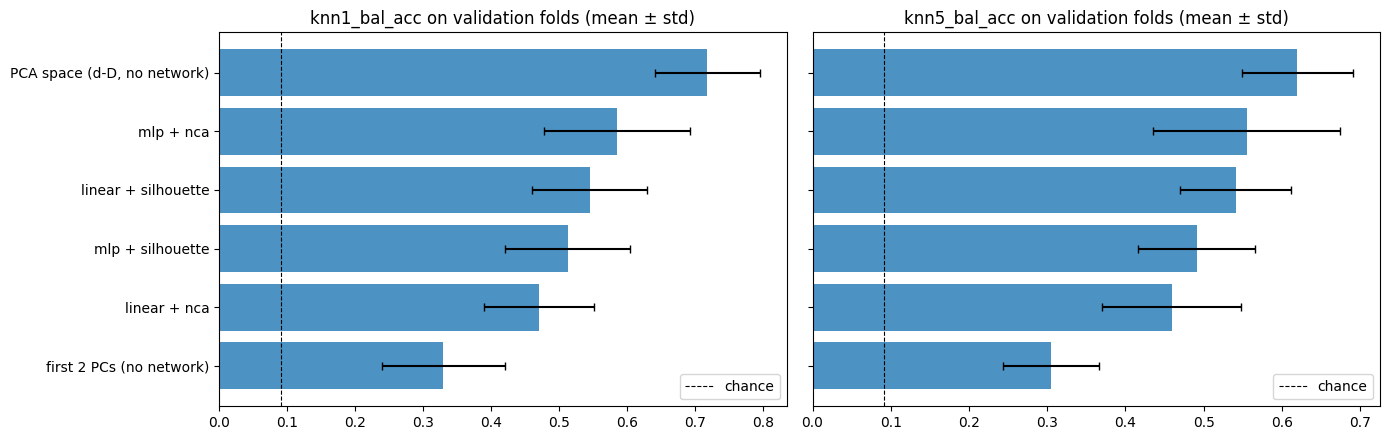

In [26]:
METRICS = ["knn1_acc", "knn1_bal_acc", "knn5_acc", "knn5_bal_acc"]
summary = res.groupby("model")[METRICS].agg(["mean", "std"]).round(3)
summary = summary.sort_values(("knn1_bal_acc", "mean"), ascending=False)
print(f"{len(folds)} validation folds | chance: balanced acc = {1 / N_CLASSES:.3f}, "
      f"always-predict-class-0 acc = {overall[0]:.3f}")
display(summary)

order = summary.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, m in zip(axes, ["knn1_bal_acc", "knn5_bal_acc"]):
    ax.barh(order, summary[(m, "mean")], xerr=summary[(m, "std")], color="C0", alpha=.8, capsize=3)
    ax.set(title=f"{m} on validation folds (mean ± std)")
    ax.invert_yaxis()
    ax.axvline(1 / N_CLASSES, c="k", ls="--", lw=.8, label="chance")
    ax.legend()
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

In [27]:
# Paired comparison: MLP minus linear, same loss, same fold (positive = non-linearity helps)
piv = res.pivot_table(index="fold", columns="model", values=["knn1_bal_acc", "knn5_bal_acc"])
rows = []
for loss_name in LOSSES:
    for m in ["knn1_bal_acc", "knn5_bal_acc"]:
        diff = piv[(m, f"mlp + {loss_name}")] - piv[(m, f"linear + {loss_name}")]
        rows.append(dict(loss=loss_name, metric=m, mean_diff=diff.mean(), std_diff=diff.std(),
                         folds_mlp_better=f"{(diff > 0).sum()}/{len(diff)}"))
pd.DataFrame(rows).round(3)

,loss,metric,mean_diff,std_diff,folds_mlp_better
0,nca,knn1_bal_acc,0.115,0.087,14/15
1,nca,knn5_bal_acc,0.096,0.102,12/15
2,silhouette,knn1_bal_acc,-0.032,0.107,5/15
3,silhouette,knn5_bal_acc,-0.049,0.091,3/15


### 7.4 Learning curves (validation metrics vs training step, mean over folds)

Use these to judge whether `N_STEPS` is sensible. If the validation curve peaks early and then falls, the model is
overfitting: lower `N_STEPS` (or raise regularization) **for all models** and re-run, rather than picking the best step per fold.

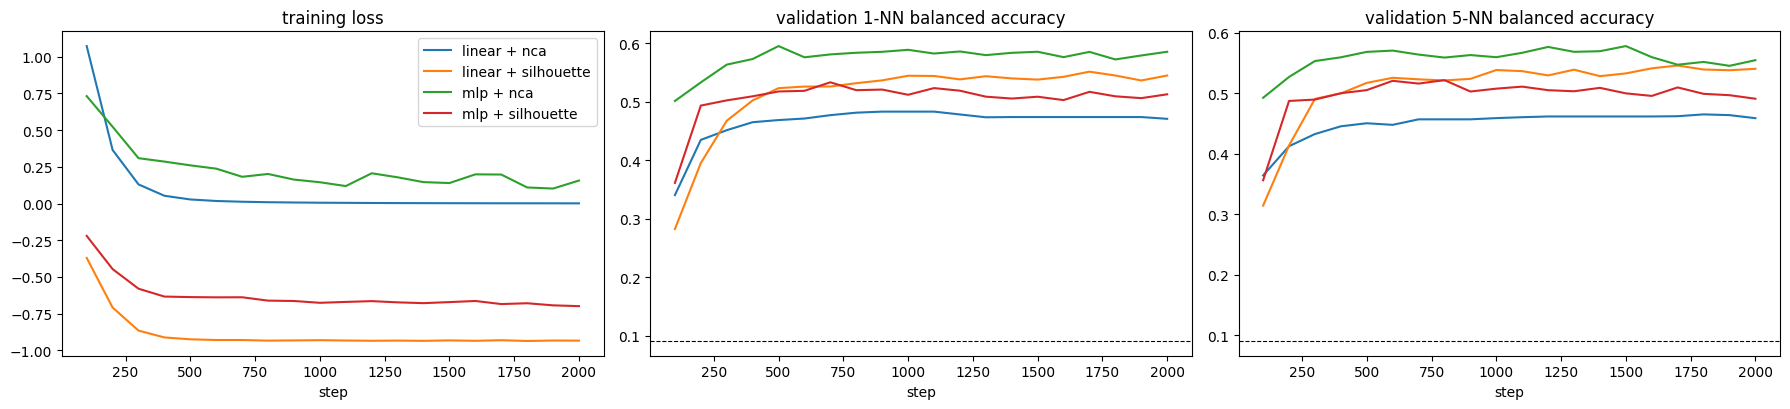

In [28]:
curves = hist_df.groupby(["model", "step"])[["train_loss", "knn1_bal_acc", "knn5_bal_acc"]].mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for i, name in enumerate(curves.model.unique()):
    c = curves[curves.model == name]
    axes[0].plot(c.step, c.train_loss, label=name, color=f"C{i}")
    axes[1].plot(c.step, c.knn1_bal_acc, label=name, color=f"C{i}")
    axes[2].plot(c.step, c.knn5_bal_acc, label=name, color=f"C{i}")
axes[0].set(title="training loss", xlabel="step")
axes[1].set(title="validation 1-NN balanced accuracy", xlabel="step")
axes[2].set(title="validation 5-NN balanced accuracy", xlabel="step")
for ax in axes[1:]:
    ax.axhline(1 / N_CLASSES, c="k", ls="--", lw=.8)
axes[0].legend()
plt.tight_layout()
plt.show()

### 7.5 What the 2-D embeddings look like (fold 0)

Small circles: training points of this fold. Large stars with a black edge: held-out validation points.
A good embedding puts each star among the circles of its own colour.

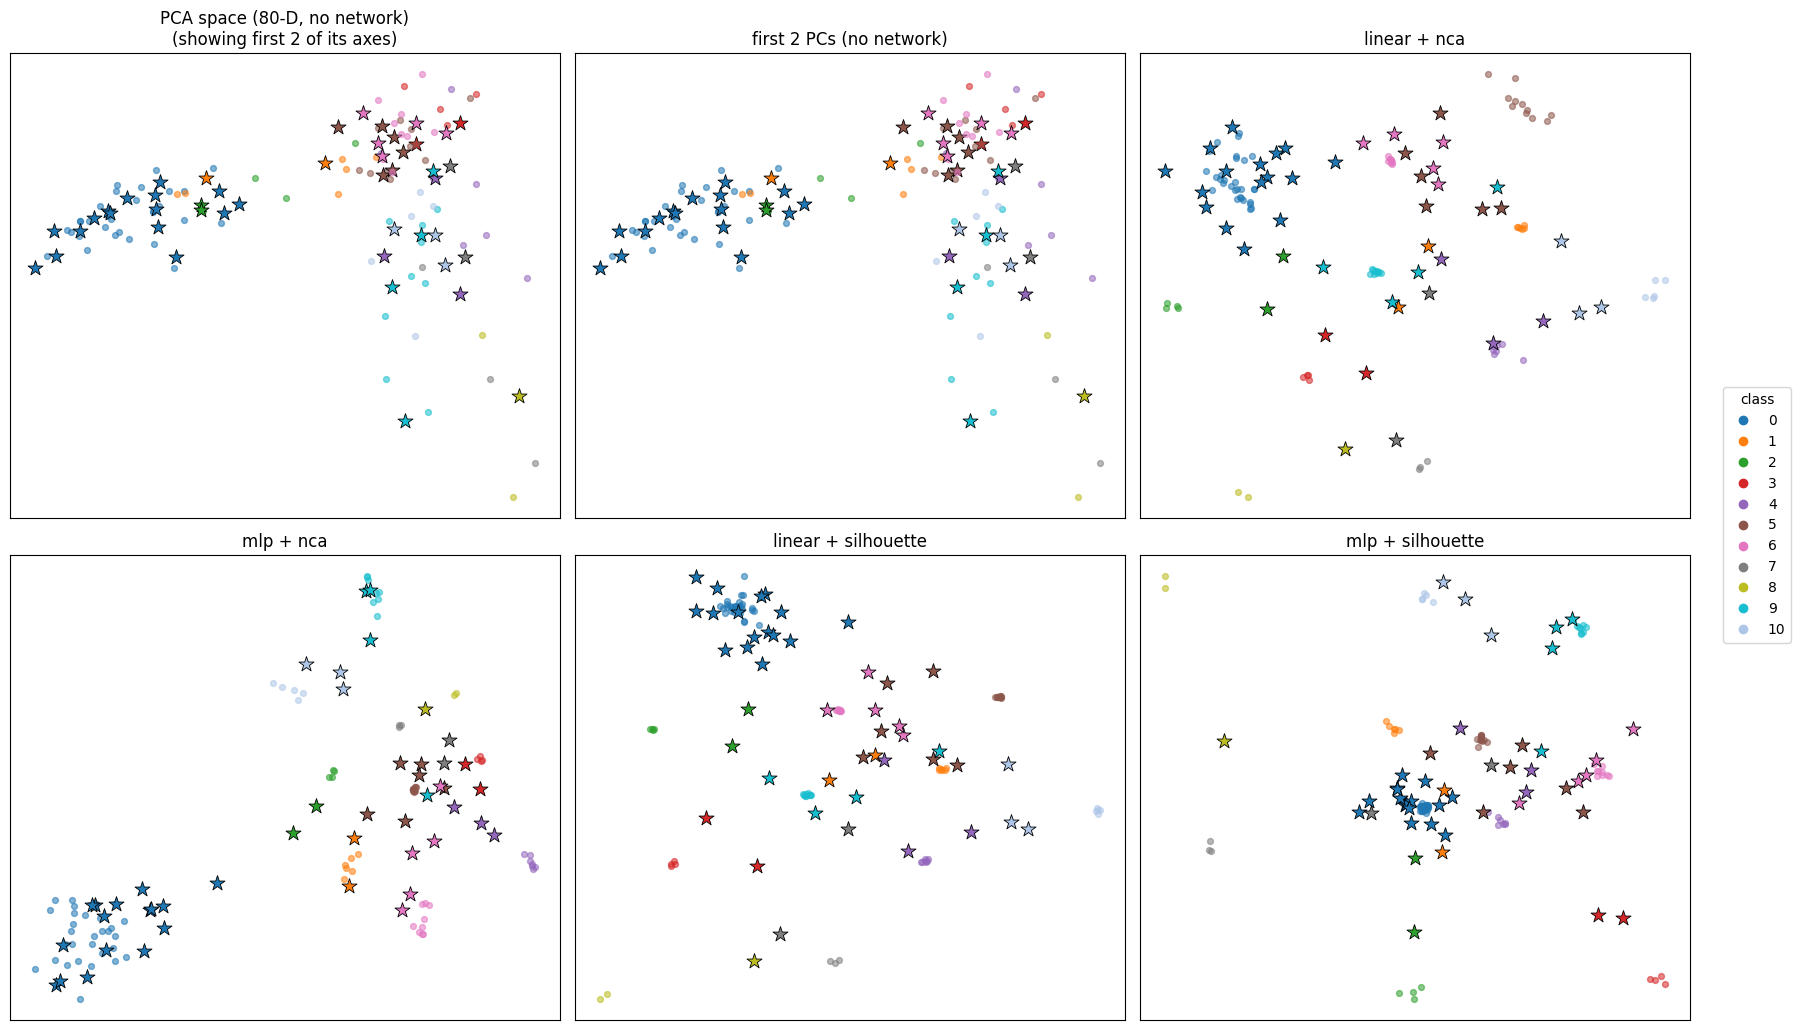

In [30]:
names = list(fold0)
ncol = 3
nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 5.2 * nrow))
axes = np.atleast_1d(axes).ravel()
for ax, name in zip(axes, names):
    E_tr, E_va, y_tr, y_va = fold0[name]
    if E_tr.shape[1] > 2:          # the full PCA space can't be drawn; show its first 2 axes
        E_tr, E_va = E_tr[:, :2], E_va[:, :2]
        name += "\n(showing first 2 of its axes)"
    for c in range(N_CLASSES):
        ax.scatter(*E_tr[y_tr == c].T, s=18, color=CLASS_COLORS[c], alpha=.55)
        ax.scatter(*E_va[y_va == c].T, s=130, marker="*", color=CLASS_COLORS[c], edgecolor="k", lw=.6)
    ax.set(title=name, xticks=[], yticks=[])
for ax in axes[len(names):]:
    ax.axis("off")
handles = [plt.Line2D([], [], marker="o", ls="", color=CLASS_COLORS[c], label=str(c)) for c in range(N_CLASSES)]
fig.legend(handles=handles, title="class", loc="center right")
plt.tight_layout(rect=(0, 0, .95, 1))
plt.show()